# PROBLEMA 4: Classificação de Risco de Crédito Utilizando Árvores de Decisão

Nesse projeto, devo construir **um modelo de classificação de solicitantes de crédito em duas categorias de risco (bom pagador e mau pagador) a partir de dados cadastrais e financeiros, utilizando uma Árvore de Decisão**.

#  Coisas que devo fazer no Dataset

1. Preparação dos dados: carregue o dataset, identifique quais atributos são numéricos e quais são categóricos. Verifique se existe necessidade de codificação adequada às variáveis categóricas (one-hot encoding ou ordinalencoding). Avalie o balanceamento entre as classes e comente o impacto de um conjunto desbalanceado (70%/30%) sobre a interpretação da acurácia.

2. Justifique por que a normalização dos atributos não é necessária para uma árvore de decisão.

3. Divisão treino/teste: divida os dados em 80% para treino e 20% para teste, utilizando divisão estratificada para garantir que a proporção das duas classes seja mantida em ambos os conjuntos.

4. Treinamento e controle de complexidade: treine árvores com diferentes valores de profundidade máxima (ex: 2, 3, 5, 7, 10 e sem limite), utilizando validação cruzada de 5 folds sobre o conjunto de treino. Plote, em um mesmo gráfico, a acurácia média de treino e a de validação em função da profundidade, e escolha o valor com melhor desempenho. O que acontece com o modelo para profundidades muito baixas e muito altas? Relacione sua resposta aos conceitos de underfitting e overfitting. Repita o experimento trocando o critério de divisão dos nós de Gini para entropia e comente se houve diferença relevante.

5. Interpretação do modelo: usando a árvore com a profundidade escolhida, gere a visualização gráfica da árvore e a lista de importância dos atributos. Responda: quais são os três atributos mais determinantes para a classificação? Escreva, em linguagem natural, o conjunto de regras correspondente ao caminho que leva da raiz até a folha com maior número de amostras de mau risco.

6. Avaliação do modelo: utilizando o conjunto de teste, calcule a matriz de confusão e as métricas de acurácia, precisão, recall e F1-score para cada classe. Responda: qual tipo de erro o modelo comete com mais frequência e por que ele é o mais grave nesta aplicação? Que ajuste você faria no treinamento para reduzi-lo ?

---

**Observação**: os atributos categóricos do arquivo german.data aparecem codificados (A11, A12, . . . ), com o significado de cada código descrito no arquivo german.doc. Alternativamente, a versão com rótulos legı́veis pode ser obtida diretamente via:

```
sklearn.datasets.fetch openml(name=’credit-g’, version=1)
```

In [113]:
# importando as  bibliotecas inicias

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

In [114]:
from sklearn.datasets import fetch_openml

# carregando o dataset já com os nomes das colunas e valores decodificados
credit_g = fetch_openml(name= 'credit-g', version= 1, as_frame= True)

# separando features e target
X = credit_g.data
y = credit_g.target

# juntando as colunas de features + target
df = pd.concat([X,y], axis= 1)

df.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


## 1. Preparação dos dados: carregue o dataset, identifique quais atributos são numéricos e quais são categóricos. Verifique se existe necessidade de codificação adequada às variáveis categóricas (one-hot encoding ou ordinalencoding). Avalie o balanceamento entre as classes e comente o impacto de um conjunto desbalanceado (70%/30%) sobre a interpretação da acurácia.

Primeiramente iremos identificar quais dos atributos são numéricos e quais são categóricos. 


In [115]:
atributos_numericos = X.select_dtypes(include=['int64', 'float64', 'number']).columns.tolist()
atributos_categoricos = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

print(f"Total de Features: {X.shape[1]}")
print(f"Quantidade de atributos numéricos: {len(atributos_numericos)}")
print("Atributos Numéricos:\n", atributos_numericos)

print(f"\nQuantidade de atributos categóricos: {len(atributos_categoricos)}")
print("Atributos Categóricos:\n", atributos_categoricos)

Total de Features: 20
Quantidade de atributos numéricos: 7
Atributos Numéricos:
 ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Quantidade de atributos categóricos: 13
Atributos Categóricos:
 ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']


No final, podemos distinguir pelo tipo da variável quais delas são features numéricas e features categóricas.

In [116]:
# verificando  os valores nulos
print("\nValores nulos em X:", X.isna().sum().sum())
print("Valores nulos em y:", y.isna().sum().sum())


Valores nulos em X: 0
Valores nulos em y: 0


Antes de continuar, podemos observar que não temos valores nulos nem no conjunto de features `X` e nem na variável target `y`. Nesse caso, não há necessidade de realizar tratamento para os dados faltantes. 

--- 

Agora iremos verificar se existe a necessidade de codificação para as variáveis categóricas: Mesmo sem a codificação dessas features, um modelo de árvore de decisão teoricamente é capaz de realizar as predições do modelo sem a necessidade de codificação. A questão é que **torna-se necessário codificar as features categóricas por conta da limitação técnica da biblioteca sk-learn** que será aplicada, pois a `DecisionTreeClassifier` foi escrita com base no cálculo de matrizes numéricas do tipo `float32`. Ou seja, nessa função, as decisões dos nós de cada árvore são calculadas.

A conversão será feita **utilizando o one-hot enconding** pois, dessa forma, a codificação das variáveis categóricas se dará por meio da criação de colunas binárias (0's ou 1's) para cada opção de categoria de uma feature. 

Caso fosse utilizado o ordinal enconding, ele iria atribuir números arbitrários para cada categoria da feature. Por exemplo, na feature `housing`:

- `own` poderia ser 0 
- `for free` poderia ser 1
- `rent` poderia ser 2

In [117]:
df['housing'].unique()

['own', 'for free', 'rent']
Categories (3, str): ['for free', 'own', 'rent']

O uso de ordinal encoding aqui poderia ser considerado indevido por que a feature `housing` não possui uma hierarquia natural. Nesse sentido, ao atribuir 0, 1, e 2, uma relação hierárquica seria imposta de forma artificial ($0 < $1 < $2). Por isso que seria mais interessante trabalhar com o one hot encoding (por meio do `pd.get_dummies()`).

Tendo em mente que iremos converter os atributos categóricos para numéricos para termos todas as features no formato numérico para utilizar o `DecisionTreeClassifier`, iremos utilizar o enconding logo abaixo da seguinte forma:

1. Pega a lista de `atributos_categoricos`
2. Para cada categoria existente dentro das colunas, cria uma nova coluna com sufixo referente a uma categoria da feature. Exemplo: `housing_own`, `housing_for_free`, `housing_rent`
3. Aplicar o parâmetro `dtype= int` para garantir a conversão das colunas em números inteiros de 0 e 1 (ao invés de valores boleanos)

Vale mencionar que as demais features que já são originalmente numéricas não são mexidas. 

In [ ]:
# aplicando one hot enconding por pd.get_dummies
X_encoded = pd.get_dummies(X, columns= atributos_categoricos, dtype= int)

# conferindo antes e pós encoding
print(f"Dimensões antes da codificação: {X.shape}")
print(f"Dimensões após o One-Hot Encoding: {X_encoded.shape}")

# juntando com o df total
df = pd.concat([X_encoded,y], axis= 1)

Dimensões antes da codificação: (1000, 20)
Dimensões após o One-Hot Encoding: (1000, 61)


Agora vamos **avaliar o balanceamento das classes** observando a proporção de rótulos de cada uma delas na variável target.

In [119]:
contagem = y.value_counts()
percentual = y.value_counts(normalize= True) * 100 

print("\nQuantidade de amostras por classe:")
print(contagem)
print("\nPercentual de amostras por classe (%):")
print(percentual.round(2))


Quantidade de amostras por classe:
class
good    700
bad     300
Name: count, dtype: int64

Percentual de amostras por classe (%):
class
good    70.0
bad     30.0
Name: proportion, dtype: float64


Podemos observar que das 1000 amostras, **temos uma proporção entre as duas classes que está claramente desbalanceada**: sendo o rótulo `good` classificado como classe majoritária com 70% dos rótulos predominantes enquanto `bad` é a classe minoritária com 30% dos rótulos.

Nesse sentido, pelo fato de que existe o desbalanceamento da classe, o modelo ficará enviesado em realizar predições e colocar o rótulo como `good` justamente porque a proporção menor de `bad` faz com que as características para atribuir uma amostra como má, sejam esmagadas e, consequentemente, o modelo só vai conseguir aprender os padrões de amostras com o rótulo `good`.

Isso significa que **a acurácia pode até tender a ser alta, mas ela acaba se revelando como um valor "mentiroso"** pois a tendência é que a maioria dos dados seja com o rótulo `good`, logo, o modelo vai acertar com mais frequência. Contudo, o modelo vai acabar se tornando péssimo em prever casos de `bad` por conta do enviesamento da árvore de decisão.

**Em termos de projeto, o desbalanceamento acaba se tornando algo péssimo** pois o mais importante nesse caso, é minimizar o erro dos rótulos `bad`. Afinal, um dos principais intuitos da construção desse algoritmo é detectar um cliente inadimplente `bad`, para evitar prejuízo direto para o banco. 

---

Por mais que essa questão do desbalanceamento dos dados não seja tratada, a utilização do stratify garante que a proporção (70/30), seja replicada identicamente para os conjuntos e no teste para evitar viés de amostragem. 

## 2. Justifique por que a normalização dos atributos não é necessária para uma árvore de decisão.

Inicialmente, quando plotamos o boxplot para verificar a necessidade de normalização, vemos que o valor do empréstimo (de `credit_amount`) está em uma escala muito maior do que a dos demais e acaba esmagando visualmente todas as outras features no gráfico.

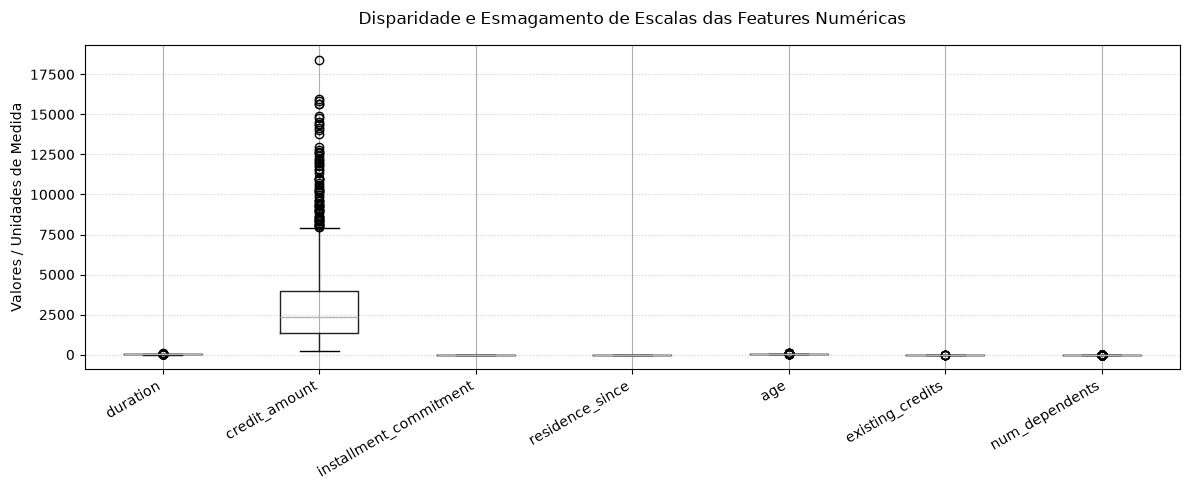

,min,mean,max
duration,4.0,20.903,72.0
credit_amount,250.0,3271.258,18424.0
installment_commitment,1.0,2.973,4.0
residence_since,1.0,2.845,4.0
age,19.0,35.546,75.0
existing_credits,1.0,1.407,4.0
num_dependents,1.0,1.155,2.0


In [120]:
# 1. Plotando o boxplot de todas as features numéricas juntas
plt.figure(figsize=(12, 5))

# Usamos a lista atributos_numericos que você já definiu na Célula 5
X[atributos_numericos].boxplot()

plt.title('Disparidade e Esmagamento de Escalas das Features Numéricas', fontsize=12, pad=15)
plt.ylabel('Valores / Unidades de Medida', fontsize=10)
plt.xticks(rotation=30, ha='right', fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 2. Exibindo os valores mínimos, médios e máximos para comprovar numericamente
display(X[atributos_numericos].describe().T[['min', 'mean', 'max']])

Contudo, a forma matemática que a árvore de decisão toma as decisões é o que a torna diferente de um k-NN ou de uma Regressão Linear e o que, consequentemente, permite que ela opere sem a necessidade de normalização.

- **Uma feature é avaliada por vez**

Nos nós de uma árvore de decisão, cada nó avalia apenas uma única feature de forma isolada por vez, estabelecendo um limiar que, caso passe, vai para um lado, caso não passe, vai para o outro lado.

Dessa forma, como a árvore acaba nunca somando, multiplicando ou calculando distâncias misturando duas ou mais features na mesma equação, uma feature de escala maior (como `credit_amount`) não interfere em nada na escala de outras features de escalas menores (como `age`).

## 3. Divisão treino/teste: divida os dados em 80% para treino e 20% para teste, utilizando divisão estratificada para garantir que a proporção das duas classes seja mantida em ambos os conjuntos.

In [121]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, random_state=42, test_size= 0.2, stratify= y)

print('Quantidade de amostras de treino: ', X_train.shape[0])
print('Quantidade de amostras de teste:', X_test.shape[0])

# verificando a proporção de classes dos conjuntos splitados
print("\nProporção no Treino (%):\n", (y_train.value_counts(normalize=True)*100).round(2))
print("\nProporção no Teste (%):\n", (y_test.value_counts(normalize=True)*100).round(2))

Quantidade de amostras de treino:  800
Quantidade de amostras de teste: 200

Proporção no Treino (%):
 class
good    70.0
bad     30.0
Name: proportion, dtype: float64

Proporção no Teste (%):
 class
good    70.0
bad     30.0
Name: proportion, dtype: float64


## 4. Treinamento e controle de complexidade: treine árvores com diferentes valores de profundidade máxima (ex: 2, 3, 5, 7, 10 e sem limite), utilizando validação cruzada de 5 folds sobre o conjunto de treino. Plote, em um mesmo gráfico, a acurácia média de treino e a de validação em função da profundidade, e escolha o valor com melhor desempenho. O que acontece com o modelo para profundidades muito baixas e muito altas? Relacione sua resposta aos conceitos de underfitting e overfitting. Repita o experimento trocando o critério de divisão dos nós de Gini para entropia e comente se houve diferença relevante.

A primeira coisa a ser feita será registrar em um array as profundidades que serão utilizadas para testar diferentes árvores. Em seguida, criaremos listas para armazenar as médias de acurácia do conjunto de treino e de validação de cada árvore.

Só então será iniciado o processo de validação cruzada..

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate 

# lista de profundidades que serão testadas e as suas respectivas labels
profundidades = [2,3,5,7,10, None]
rotulos_profundidades = ['2','3','5','7','10', 'Sem limite']

# lista para armazenar medias de acurácia
gini_treino_medias= []
gini_val_medias= []

In [ ]:
print('---- Validação Cruzada (5 folds), utilizando o critério de GINI ----\n')

for d, rotulo in zip(profundidades, rotulos_profundidades):
    # primeiramente instânciar o modelo preditivo
    arvore = DecisionTreeClassifier(max_depth= d, criterion='gini', random_state=42)

    # validação cruzada calculando acurácia no treino e na validação
    cv_res = cross_validate(arvore, X_train, y_train, cv= 5, scoring= 'accuracy', return_train_score= True)

    # extraindo as médias de treino e validação 
    media_treino = cv_res['train_score'].mean()
    media_val = cv_res['test_score'].mean()

    #extraindo as médias de gini de treino e de validação
    gini_treino_medias.append(media_treino)
    gini_val_medias.append(media_val)

    print(f"max_depth = {rotulo:>10} | Acurácia Treino = {media_treino:.4f} | Acurácia Validação = {media_val:.4f}")

---- Validação Cruzada (5 folds), utilizando o critério de GINI ----

max_depth =          2 | Acurácia Treino = 0.7225 | Acurácia Validação = 0.7063
max_depth =          3 | Acurácia Treino = 0.7447 | Acurácia Validação = 0.6925
max_depth =          5 | Acurácia Treino = 0.8059 | Acurácia Validação = 0.6950
max_depth =          7 | Acurácia Treino = 0.8634 | Acurácia Validação = 0.6950
max_depth =         10 | Acurácia Treino = 0.9381 | Acurácia Validação = 0.6962
max_depth = Sem limite | Acurácia Treino = 1.0000 | Acurácia Validação = 0.6813


É possível então plotar um gráfico para comparar as curvas de treino e de validação baseadas no critério de Gini. A imagem está referenciada logo abaixo: 

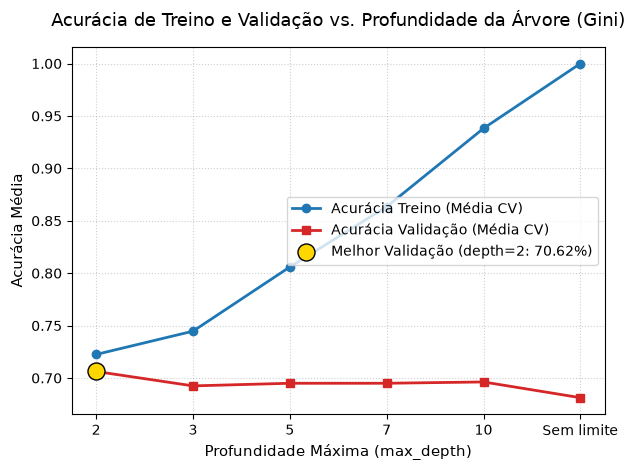

In [124]:
plt.plot(rotulos_profundidades, gini_treino_medias, marker='o', linewidth=2, color='#1f77b4', label='Acurácia Treino (Média CV)')
plt.plot(rotulos_profundidades, gini_val_medias, marker='s', linewidth=2, color='#d62728', label='Acurácia Validação (Média CV)')

# identificando o melhor ponto de validação
melhor_idx_gini = np.argmax(gini_val_medias)
melhor_prof_gini = rotulos_profundidades[melhor_idx_gini]
melhor_score_gini = gini_val_medias[melhor_idx_gini]

plt.scatter(melhor_prof_gini, melhor_score_gini, color='gold', s=150, zorder=5, edgecolor='black', label=f'Melhor Validação (depth={melhor_prof_gini}: {melhor_score_gini*100:.2f}%)')
plt.title('Acurácia de Treino e Validação vs. Profundidade da Árvore (Gini)', fontsize=13, pad=15)
plt.xlabel('Profundidade Máxima (max_depth)', fontsize=11)
plt.ylabel('Acurácia Média', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='center right', fontsize=10)

plt.tight_layout()
plt.show()

Agora aplicar a mesma **validação cruzada** trocando apenas o critério: agora ao invés de ser Gini, será por entropia. Logo após isso, será realizada a comparação dos resultados.

In [125]:
profundidades = [2, 3, 5, 7, 10, None]
rotulos_profundidades = ['2', '3', '5', '7', '10', 'Sem limite']

entropy_treino_medias = []
entropy_val_medias = []

print("--- Validação Cruzada (5 Folds) - Critério ENTROPIA ---\n")

for d, rotulo in zip(profundidades, rotulos_profundidades):
    arvore = DecisionTreeClassifier(max_depth=d, criterion='entropy', random_state=42)
    cv_res = cross_validate(arvore, X_train, y_train, cv=5, scoring='accuracy', return_train_score=True)
    
    media_treino = cv_res['train_score'].mean()
    media_val = cv_res['test_score'].mean()
    
    entropy_treino_medias.append(media_treino)
    entropy_val_medias.append(media_val)
    
    print(f"max_depth = {rotulo:>10} | Acurácia Treino = {media_treino:.4f} | Acurácia Validação = {media_val:.4f}")

--- Validação Cruzada (5 Folds) - Critério ENTROPIA ---

max_depth =          2 | Acurácia Treino = 0.7128 | Acurácia Validação = 0.7063
max_depth =          3 | Acurácia Treino = 0.7322 | Acurácia Validação = 0.7013
max_depth =          5 | Acurácia Treino = 0.7934 | Acurácia Validação = 0.7100
max_depth =          7 | Acurácia Treino = 0.8428 | Acurácia Validação = 0.6925
max_depth =         10 | Acurácia Treino = 0.9163 | Acurácia Validação = 0.6825
max_depth = Sem limite | Acurácia Treino = 1.0000 | Acurácia Validação = 0.6800


In [126]:
# tabela para comparar a validação de GINI vs ENTROPIA
df_comparacao = pd.DataFrame({
    'max_depth': rotulos_profundidades,
    'Validação (Gini)': gini_val_medias,
    'Validação (Entropia)': entropy_val_medias,
    'Diferença Absoluta': np.abs(np.array(gini_val_medias) - np.array(entropy_val_medias))
})
print("\n--- Comparativo de Desempenho na Validação: Gini vs Entropia ---")
display(df_comparacao.round(4))


--- Comparativo de Desempenho na Validação: Gini vs Entropia ---


,max_depth,Validação (Gini),Validação (Entropia),Diferença Absoluta
0,2,0.7062,0.7062,0.0000
1,3,0.6925,0.7012,0.0087
2,5,0.6950,0.7100,0.0150
3,7,0.6950,0.6925,0.0025
4,10,0.6962,0.6825,0.0137
5,Sem limite,0.6812,0.6800,0.0012


- **Gini x Entropia**

Ao comparar as diferenças da acurácia de validação entre Gini e Entropia, é possível notar que ela foi bem baixa no geral à medida que a profundidade máxima da árvore ia aumentando. Isso mostra que por mais que os critérios de impureza aplicados ao algoritmo sejam distintos, eles tomam decisões de divisão similares na vasta maioria dos nós mesmo com o aumento da profundidade da árvore de decisão.

---

A partir da comparação de desempenho utilizando as duas validações diferentes, podemos tirar algumas conclusões a respeito da profundidade da árvore com relação ao clássico trade-off do viés e da variância. 

- **Árvores com profundidades muito baixas tendem ao underfitting**

Em exemplos onde a árvore realiza uma quantidade reduzida de divisões (por exemplo, `max_depth = 2`) acaba gerando um modelo excessivamente limitado e incapaz de capturar as relações reais entre os dados. Isso é refletido diretamente quando analisamos a curva de acurácia de treino e comparamos com as árvores de profundidades mais baixas.

Ou seja, pelo fato delas não conseguirem captar condições muito complexas, essas árvores se restringem apenas a poucas condições, o que pode tornar ela enviesada ao ponto de levar em consideração apenas algumas variáveis que foram postas nas poucas condições de bifurcação dos nós, já que a árvore possui baixa profundidade.

- **Árvores com profundidades muito altas tendem ao overfitting**

Em exemplos onde a árvore realiza uma quantidade excessiva de divisões (por exemplo, `max_depth = 10 ou Sem limite`) acaba gerando um modelo que cresce livremente até criar folhas quase puras. Contudo, a quantidade excessiva de condições de separação entre os nós intermediários acaba gerando uma condição de alta variância, caracterizando assim o overfitting do modelo. 

Logo, por mais que a acurácia atinja 100%, o modelo perde a capacidade de generalização e a acurácia de validação ou atinje um platô ou cai mais ainda.

- **A melhor profundidade**

O ponto ótimo de equilíbrio encontrado entre viés e variância para esta validação cruzada ocorreu em profundidades que não foram nem as menores e nem as maiores: `max_depth = 5`.

## 5. Interpretação do modelo: usando a árvore com a profundidade escolhida, gere a visualização gráfica da árvore e a lista de importância dos atributos. Responda: quais são os três atributos mais determinantes para a classificação? Escreva, em linguagem natural, o conjunto de regras correspondente ao caminho que leva da raiz até a folha com maior número de amostras de mau risco.

Com a profundidade escolhida, vou usar a função do sklearn para plotar a árvore de decisão por meio do `plot_tree`, treinar essa árvore com a profundidade escolhida usando o conjunto de dados de treino, extrair a importância de cada atributo do modelo e plotar a árvore para ver a representação gráfica.

In [127]:
from sklearn.tree import plot_tree

profundidade_escolhida = 5 
arvore_final = DecisionTreeClassifier(max_depth= profundidade_escolhida, criterion= 'gini', random_state= 42)

arvore_final.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

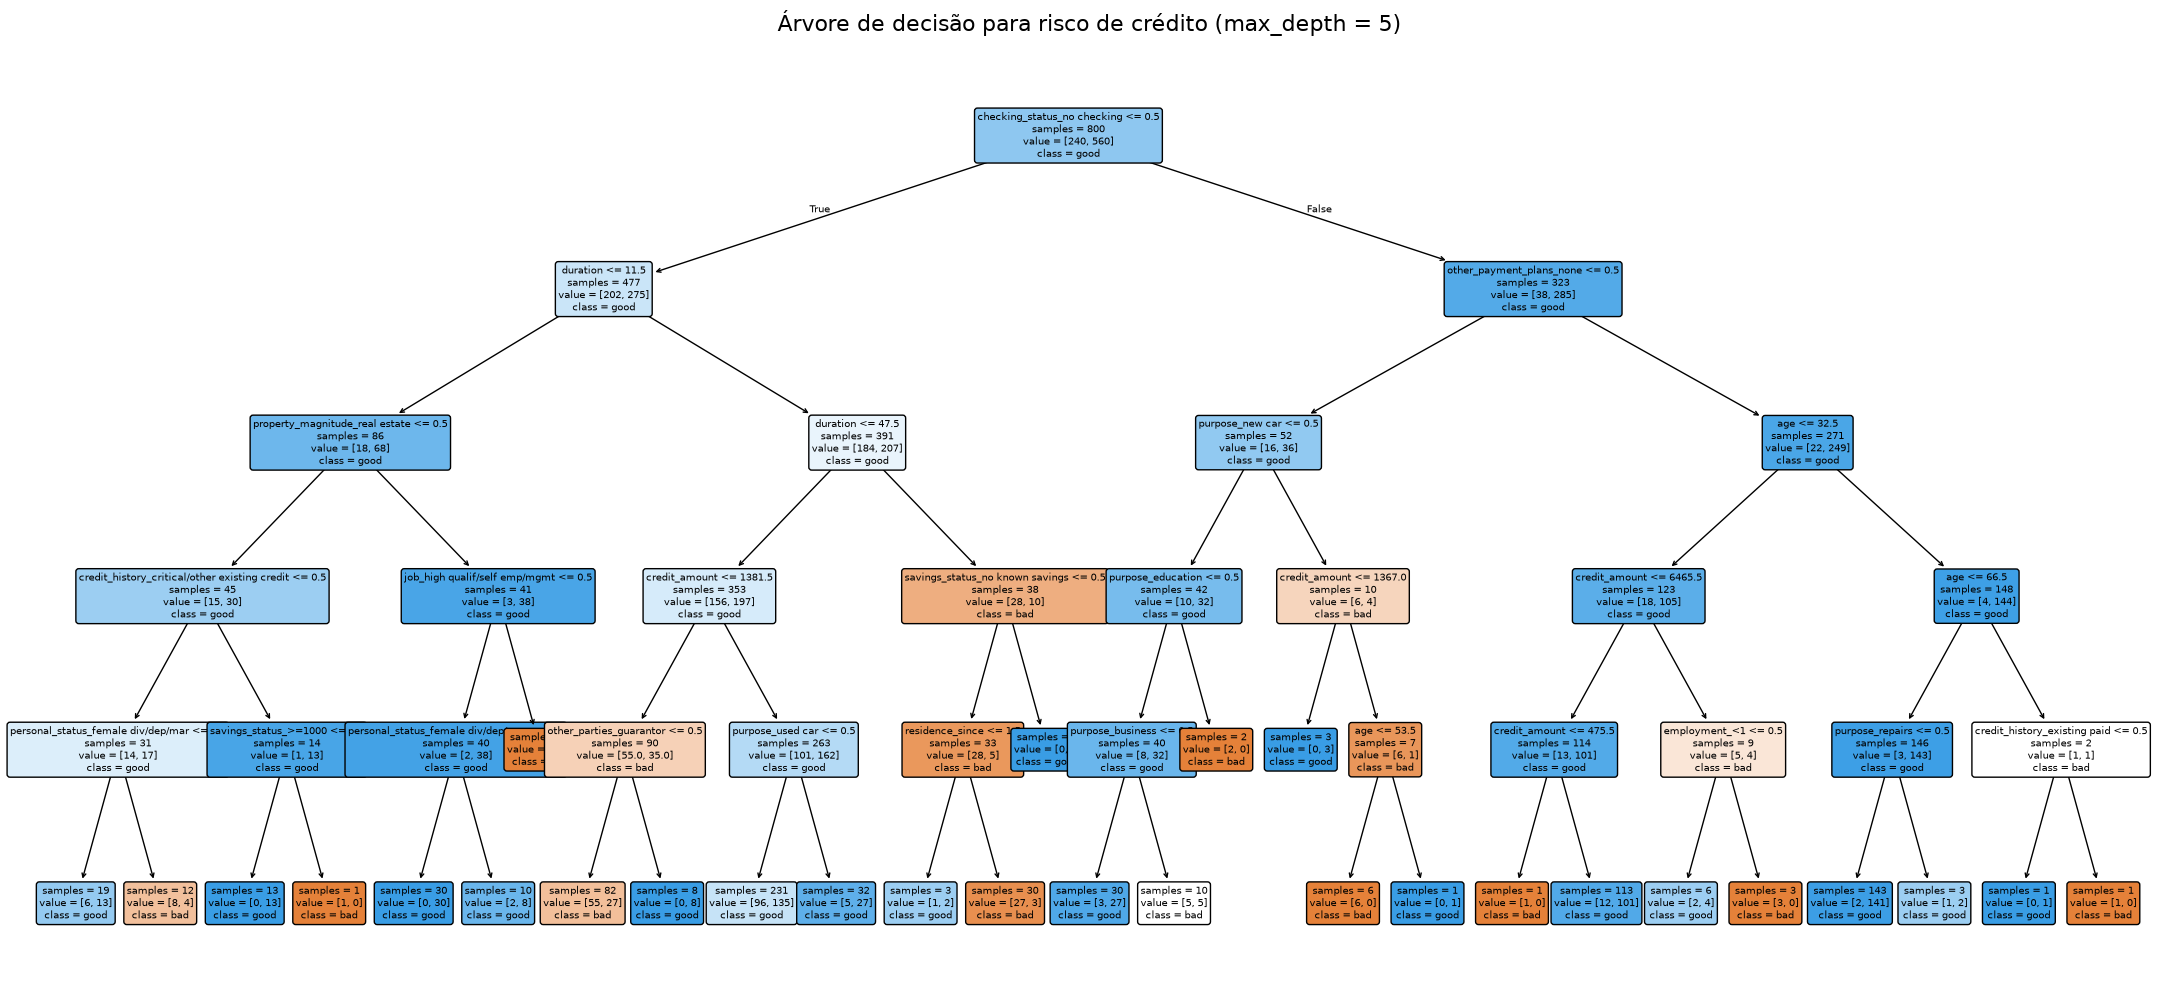

In [ ]:
# plotting da árvore
plt.figure(figsize=(22, 10))
plot_tree(
    arvore_final,
    feature_names=X_train.columns.tolist(),
    class_names=arvore_final.classes_.tolist(), # ['bad', 'good']
    filled=True,
    rounded=True,
    fontsize=5,
    impurity= False, # remover linha gini = ...
    precision= 2 # limitar números de flutuantes
)
plt.title(f'Árvore de decisão para risco de crédito (max_depth = {profundidade_escolhida})', fontsize=16, pad=20)
plt.tight_layout()

plt.savefig('arvore_decisao.png', dpi=300, bbox_inches='tight')

plt.show()

A partir do gráfico e do `export_text`, o nó-folha com a maior concentração de risco possui 82 amostras no total, das quais 55 são da classe `bad` e 27 da classe `good` (sendo a folha classificada como bad com maior volume absoluto de inadimplentes da árvore).

O caminho para acessar esse nó-folha é o descrito logo abaixo:

> Se o cliente possui conta corrente cadastrada no banco (`checking_status_no checking <= 0.5`)  
> E a duração do empréstimo for superior a 12 meses (`duration > 11.5`)  
> E a duração do empréstimo for menor ou igual a 47 meses (`duration <= 47.5`)  
> E o valor do crédito solicitado for relativamente baixo, até 1.381 DM (`credit_amount <= 1381.5`)  
> E o solicitante não possui garantidor ou fiador (`other_parties_guarantor <= 0.5`)  
> ENTÃO o risco de crédito é classificado como **MAU PAGADOR (`bad`)**.

---

Agora será printado a estrutura em formato de texto para conferir os pesos e os nós da árvore com mais clareza utilizando o `export_text` da sklearn.

In [129]:
from sklearn.tree import export_text

regras_texto = export_text(
    arvore_final, feature_names= X_train.columns.tolist(), show_weights= True
)

print(regras_texto)

|--- checking_status_no checking <= 0.50
|   |--- duration <= 11.50
|   |   |--- property_magnitude_real estate <= 0.50
|   |   |   |--- credit_history_critical/other existing credit <= 0.50
|   |   |   |   |--- personal_status_female div/dep/mar <= 0.50
|   |   |   |   |   |--- weights: [6.00, 13.00] class: good
|   |   |   |   |--- personal_status_female div/dep/mar >  0.50
|   |   |   |   |   |--- weights: [8.00, 4.00] class: bad
|   |   |   |--- credit_history_critical/other existing credit >  0.50
|   |   |   |   |--- savings_status_>=1000 <= 0.50
|   |   |   |   |   |--- weights: [0.00, 13.00] class: good
|   |   |   |   |--- savings_status_>=1000 >  0.50
|   |   |   |   |   |--- weights: [1.00, 0.00] class: bad
|   |   |--- property_magnitude_real estate >  0.50
|   |   |   |--- job_high qualif/self emp/mgmt <= 0.50
|   |   |   |   |--- personal_status_female div/dep/mar <= 0.50
|   |   |   |   |   |--- weights: [0.00, 30.00] class: good
|   |   |   |   |--- personal_status_fema

Agora iremos capturar as features importantes para o nosso modelo de predição baseado na árvore de decisão

In [130]:
# extraindo a importância de cada feature
importancias = pd.Series(arvore_final.feature_importances_, index= X_train.columns)

# filtrando features de importância > 0
importancias_ativas = importancias[importancias > 0].sort_values(ascending= False)

print("--- Rank de importância das features ---\n")
display(pd.DataFrame({'Importancia (gini)': importancias_ativas}).round(4))

--- Rank de importância das features ---



,Importancia (gini)
checking_status_no checking,0.3109
duration,0.1346
credit_amount,0.1281
other_parties_guarantor,0.0566
savings_status_no known savings,0.0540
age,0.0391
other_payment_plans_none,0.0386
purpose_used car,0.0326
property_magnitude_real estate,0.0251
credit_history_critical/other existing credit,0.0241


A partir do cálculo do `feature_importances_`, ele mede a redução total de impureza de Gini proporcionada por cada feature ao longo da árvore. Dessa forma, as 3 features mais determinantes e impactantes para a árvore foram:


- **`checking_status_no checking` (Importância: 31,09%)**  

Essa feature mais significativa indica se o cliente mantém saldo em conta ou se está no vermelho/sem conta ativa. Ou seja, verificar o status de situação atual do cliente é um forte fator para determinar ou não o estado de inadimplência do cliente.

Isso pode indicar um histórico financeiro desconhecido e suspeito do cliente e impacta diretamente na determinação de inadimplência do mesmo (e, consequentemente, do risco).

- **`duration` (Importância: 13,46%)**

Essa foi a segunda feature mais significativa e indica a duração do empréstimo em meses. Para casos de inadimplência do cliente, os prazos mais longos podem tender a aumentar o período de incerteza.

- **`credit_amount` (Importância: 12,81%)**

Essa foi a terceira feature mais importante e indica o valor total solicitado. Ao que tudo indica, a tendência é que quanto maior for o valor do empréstimo em relação ao perfil do cliente, maior é o impacto no compromentimento da renda (e, consequentemente, do risco).

## 6. Avaliação do modelo: utilizando o conjunto de teste, calcule a matriz de confusão e as métricas de acurácia, precisão, recall e F1-score para cada classe. Responda: qual tipo de erro o modelo comete com mais frequência e por que ele é o mais grave nesta aplicação? Que ajuste você faria no treinamento para reduzi-lo ?

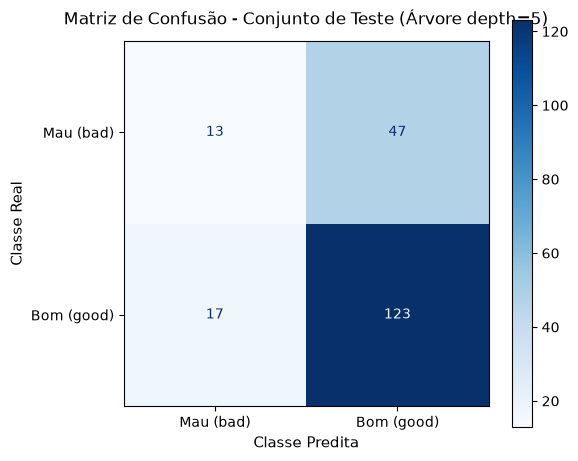

In [131]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, precision_recall_fscore_support

# 1) predição do modelo 
y_pred = arvore_final.predict(X_test)

# 2) plotting da matriz confusão
labels_classes = ['bad', 'good']
cm = confusion_matrix(y_test, y_pred, labels= labels_classes)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=['Mau (bad)', 'Bom (good)']
)
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title("Matriz de Confusão - Conjunto de Teste (Árvore depth=5)", fontsize=12, pad=12)
plt.xlabel("Classe Predita", fontsize=11)
plt.ylabel("Classe Real", fontsize=11)

plt.grid(False)
plt.tight_layout()
plt.show()

In [133]:
# 3) extraindo métricas por classe
precision, recall, f1, support = precision_recall_fscore_support(y_test, y_pred, labels= labels_classes)

df_metricas = pd.DataFrame({
    'Classe': ['Mau Pagador (bad)', 'Bom pagador (good)'],
    'Precisão': precision,
    'Recall': recall, 
    'F1-Score': f1,
    'Suporte' : support 
})

print(f"--- Desempenho no teste ---\n")
print(f"Acurácia Geral: {accuracy_score(y_test, y_pred):.4f} ({accuracy_score(y_test, y_pred)*100:.2f}%)\n")
display(df_metricas.round(4))

print("\n--- Relatório de Classificação Completo ---")
print(classification_report(y_test, y_pred, labels=labels_classes, digits=4))

--- Desempenho no teste ---

Acurácia Geral: 0.6800 (68.00%)



,Classe,Precisão,Recall,F1-Score,Suporte
0,Mau Pagador (bad),0.4333,0.2167,0.2889,60
1,Bom pagador (good),0.7235,0.8786,0.7935,140



--- Relatório de Classificação Completo ---
              precision    recall  f1-score   support

         bad     0.4333    0.2167    0.2889        60
        good     0.7235    0.8786    0.7935       140

    accuracy                         0.6800       200
   macro avg     0.5784    0.5476    0.5412       200
weighted avg     0.6365    0.6800    0.6422       200



- **Interpretações da matriz confusão: existem muitos falsos negativos**

O modelo no geral apresenta uma quantidade considerável de erros durante a predição das classes para o conjunto de dados de teste. Sendo o erro que comete como muito mais frequência o de prever um solicitante "bom pagador" (`good`) quando na realidade ele é "mau pagador". 

Portanto, ele apresenta uma quantidade elevada de falsos negativos significativa e isso, em termos de projeto, é catastrófico para nós pois, basicamente, o modelo está deixando passar uma quantidade significativa de clientes inadimplentes (47), rotulando eles como "bons pagadores".

Quando observamos a proporção dos erros, observamos que justamente a quantidade de falsos negativos (47), é muito maior do que a quantidade de falsos positivos (17). Essa quantidade de falsos negativos representa certa de 73,4% dos erros cometidos e, como já mencionados, tratam-se de erros graves.

---

Vale mencionar que o erro de falsos positivos representam as pessoas que são bons pagadores que foram considerados como mal pagadores. Rejeitar a proposta de um cliente que paga bem gera um impacto considerável pois o banco perde uma oportunidade de emprestar direito. Contudo, **o erro de falso negativo aqui é muito mais significativo pois compromete diretamente a perda de capital do banco juntamente com a credibilidade do mesmo, afinal, quem confia em um banco de empresa dinheiro para um clientela duvidosa e sem compromisso**.

- **Ajustes a se fazer: Balancear o conjunto de dados**

As métricas estatísticas refletem o desempenho de um modelo que foi prejudicado principalmente por não ter lidado com um conjunto de dados composto pelos rótulos desbalanceados. Para resolver essa questão, é possível aplicar algumas técnicas para balancear o conjunto e evitar que o modelo fique enviesado. Dentre elas estão:

1. Aplicar `class_weights` para a ponderação das classes

Configurar o parâmetro `class_weight='balanced'` no construtor do modelo em `DecisionTreeClassifier`. Isso faz com que o algoritmo penalize muito mais severamente os erros cometidos na classe minoritária (`bad`) durante o cálculo de impureza de Gini/Entropia, forçando a árvore a ser mais rigorosa antes de classificar alguém como bom pagador.

2. Ajustar o limiar de decisão (threshold moving)

Em vez de aceitar a predição binária padrão de $P > 0.50$ via `.predict()`, utilizar `predict_proba()` e classificar o cliente como `bad` caso a probabilidade estimada de risco seja superior a um limiar mais conservador (por exemplo, $P(\text{bad}) > 0.30$). Nesse caso, será usado o modelo original (`arvore_final`), mas alterando a régua de corte e colocando um limiar mais rigoroso (por exemplo 30%),  pois se a chance de ser um mau cliente for >= 30%, já classifica como `bad`.

In [134]:
arvore_balanced = DecisionTreeClassifier(
    max_depth=5, 
    criterion='gini', 
    class_weight='balanced', # AJUSTE 1: ponderandoas as classes para otreinamento
    random_state=42
)
arvore_balanced.fit(X_train, y_train)
y_pred_balanced = arvore_balanced.predict(X_test)
bad_idx = np.where(arvore_final.classes_ == 'bad')[0][0] # indice da classe 'bad' nas probabilidades 
probabilidades_bad = arvore_final.predict_proba(X_test)[:, bad_idx]

limiar = 0.30 # setando o limiar
y_pred_threshold = np.where(probabilidades_bad >= limiar, 'bad', 'good')

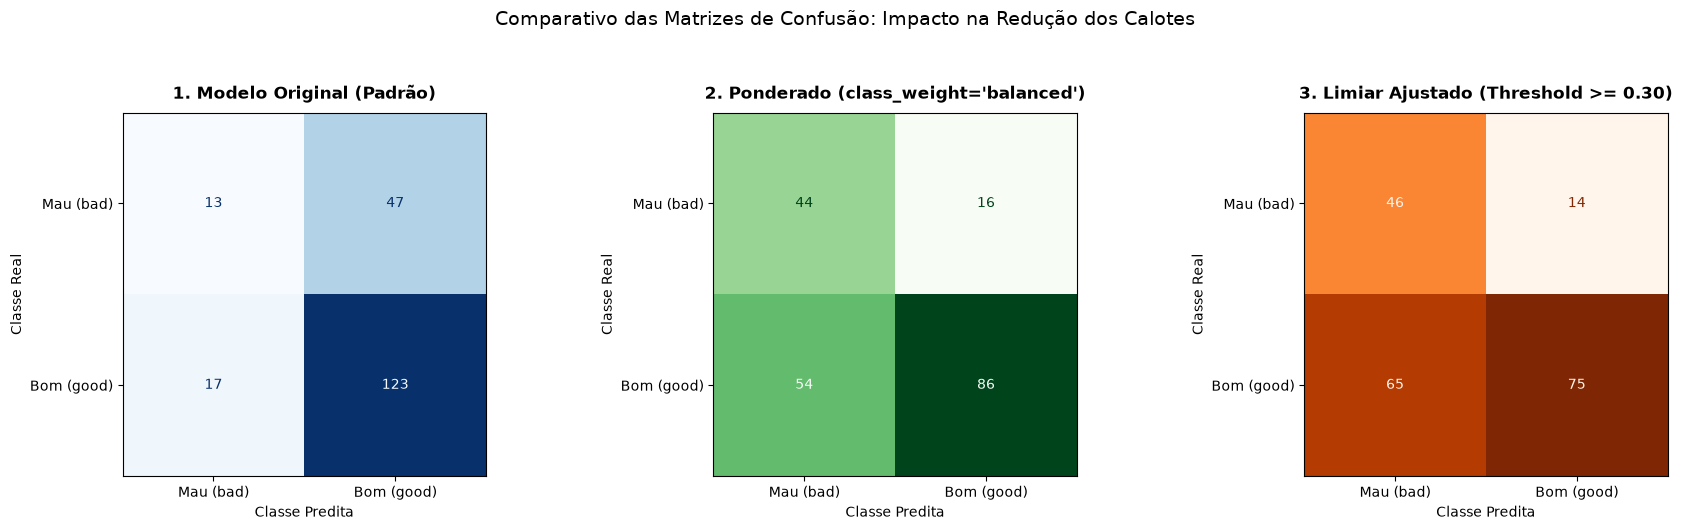

In [135]:
# Plotando as 3 matrizes confusão lado a lado
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
modelos_teste = [
    ("1. Modelo Original (Padrão)", y_pred, 'Blues'),
    ("2. Ponderado (class_weight='balanced')", y_pred_balanced, 'Greens'),
    (f"3. Limiar Ajustado (Threshold >= {limiar:.2f})", y_pred_threshold, 'Oranges')
]
for ax, (titulo, pred, mapa_cor) in zip(axes, modelos_teste):
    cm_temp = confusion_matrix(y_test, pred, labels=['bad', 'good'])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_temp, 
        display_labels=['Mau (bad)', 'Bom (good)']
    )
    disp.plot(cmap=mapa_cor, ax=ax, values_format='d', colorbar=False)
    ax.set_title(titulo, fontsize=12, pad=10, fontweight='bold')
    ax.set_xlabel("Classe Predita", fontsize=10)
    ax.set_ylabel("Classe Real", fontsize=10)
    ax.grid(False)
plt.suptitle("Comparativo das Matrizes de Confusão: Impacto na Redução dos Calotes", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

--- Comparativo Quantitativo de Desempenho ---


,Estratégia,Acurácia Geral,Recall (bad),Precisão (bad),F1-Score (bad),Calotes Aprovados (FN),Bons Rejeitados (FP)
0,1. Modelo Original (Baseline),0.680,0.2167,0.4333,0.2889,47,17
1,"2. class_weight=""balanced""",0.650,0.7333,0.4490,0.5570,16,54
2,3. Limiar Rigoroso (30%),0.605,0.7667,0.4144,0.5380,14,65


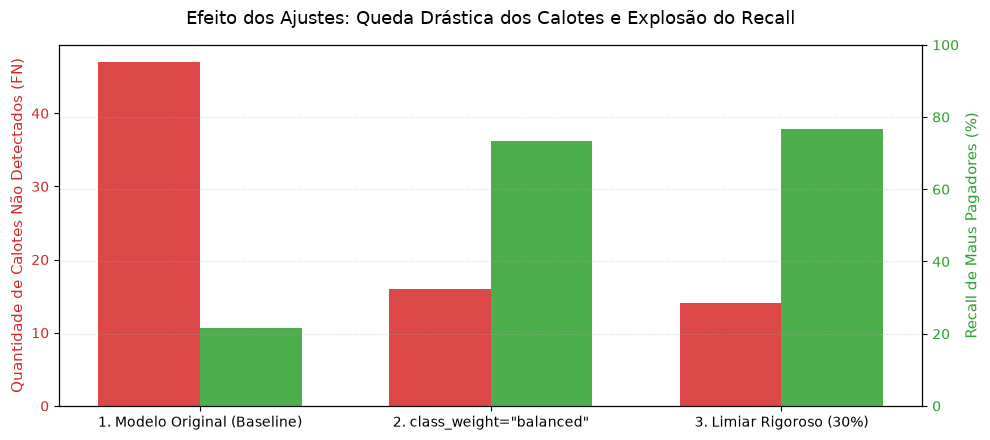

In [ ]:
def extrair_resumo(nome, y_real, y_predito):
    p, r, f1, _ = precision_recall_fscore_support(y_real, y_predito, labels=['bad', 'good'])
    cm = confusion_matrix(y_real, y_predito, labels=['bad', 'good'])
    return {
        'Estratégia': nome,
        'Acurácia Geral': accuracy_score(y_real, y_predito),
        'Recall (bad)': r[0],
        'Precisão (bad)': p[0],
        'F1-Score (bad)': f1[0],
        'Calotes Aprovados (FN)': cm[0, 1],
        'Bons Rejeitados (FP)': cm[1, 0]
    }

df_comparativo = pd.DataFrame([
    extrair_resumo('1. Modelo Original (Baseline)', y_test, y_pred),
    extrair_resumo('2. class_weight="balanced"', y_test, y_pred_balanced),
    extrair_resumo(f'3. Limiar Rigoroso ({limiar*100:.0f}%)', y_test, y_pred_threshold)
])

print("--- Comparativo Quantitativo de Desempenho ---")
display(df_comparativo.round(4))

# gráfico de barras: Falsos Negativos vs Recall da Classe 'bad'
fig, ax1 = plt.subplots(figsize=(10, 4.5))

x = np.arange(len(df_comparativo))
largura = 0.35

barras_fn = ax1.bar(x - largura/2, df_comparativo['Calotes Aprovados (FN)'], largura, label='Calotes Aprovados (FN)', color='#d62728', alpha=0.85)
ax1.set_ylabel('Quantidade de Calotes Não Detectados (FN)', color='#d62728', fontsize=11)
ax1.tick_params(axis='y', labelcolor='#d62728')
ax1.set_xticks(x)
ax1.set_xticklabels(df_comparativo['Estratégia'], fontsize=10)

ax2 = ax1.twinx()
barras_recall = ax2.bar(x + largura/2, df_comparativo['Recall (bad)'] * 100, largura, label='Recall da Classe bad (%)', color='#2ca02c', alpha=0.85)
ax2.set_ylabel('Recall de Maus Pagadores (%)', color='#2ca02c', fontsize=11)
ax2.tick_params(axis='y', labelcolor='#2ca02c')
ax2.set_ylim(0, 100)

plt.title("Efeito dos Ajustes: Queda Drástica dos Calotes e Explosão do Recall", fontsize=13, pad=15)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

1. **Impacto do `class_weight='balanced'`:**

O Recall da classe `bad` saltou de 21,67% para 73,33%, enquanto o F1-Score subiu de 0,2889 para 0,5570.
A quantidade de **calotes concedidos (Falsos Negativos) desabou de 47 para apenas 16**. Ou seja, o banco passou a interceptar **44 dos 60 clientes inadimplentes** (contra os 13 no modelo original).

O custo dessa proteção foi o aumento dos Falsos Positivos (de 17 para 54), o que reflete uma postura de crédito mais cautelosa. Em termos financeiros, essa troca é altamente vantajosa, pois a perda com um único calote supera com folga a margem de lucro de alguns clientes bons rejeitados.

2. **Impacto do Ajuste de Limiar (Threshold Moving com corte em 30%):**

* Ao exigir apenas $P(\text{bad}) \ge 0,30$ para barrar o crédito, o **Recall atingiu 76,67%**, reduzindo os calotes perdidos para apenas **14 casos**. Vale mencionar que essa abordagem tem a vantagem de não exigir o retreinamento da árvore, operando diretamente na régua de tolerância ao risco da esteira bancária.

---

No final, ambos os ajustes resolvem significativamente a deficiência estrutural do modelo original, tornando o classificador viável para uso em um ambiente financeiro real.